In [1]:
import xarray as xr
import numpy as np
import datetime
import f90nml
import glob
import os
from dask.diagnostics import ProgressBar
import datetime

from matplotlib.colors import Normalize

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.transforms as mtransforms
import matplotlib.ticker as ticker

In [2]:
def decode_binary(flxdir, ntim, nlev, nlat, nlon, linv=0):
    if linv == 0:
        inipaths = [f'{flxdir}/grid_initial_001']
        len_dummy_entries = 20

    elif linv == 1:
        inipaths = sorted(glob.glob(f'{flxdir}/grid_initial*'))[::-1]
        len_dummy_entries = 3

    sparse_dump_i = []
    sparse_dump_r = []
    for inipath in inipaths:
        offset = 4*3
        while True:
            try:
                sp_count_i = np.fromfile(inipath, dtype='<i4', count=1, offset=offset+4*(len_dummy_entries+1))[0]
                sparse_dump_i.append(np.fromfile(inipath, dtype='<i4', count=sp_count_i, offset=offset+4*(len_dummy_entries+4)))
                sp_count_r = np.fromfile(inipath, dtype='<i4', count=1, offset=offset+4*(len_dummy_entries+4+sp_count_i+2))[0]
                sparse_dump_r.append(np.fromfile(inipath, dtype='<f4', count=sp_count_r, offset=offset+4*(len_dummy_entries+4+sp_count_i+5)))
                offset += 4*(len_dummy_entries+4+sp_count_i+5+sp_count_r+1)
            except (IndexError): # end of file
                break

    inisens_1d = np.zeros((ntim,nlon*nlat*nlev))

    for t in range(ntim):
        rind = 0
        for i in range(len(sparse_dump_i[t])):
            sign = np.sign(sparse_dump_r[t][rind])
            n = 0
            while rind+n < len(sparse_dump_r[t])-1 and sparse_dump_r[t][rind+n]*sign > 0:
                inisens_1d[t, sparse_dump_i[t][i] - nlon * nlat + n] = sign * sparse_dump_r[t][rind + n]
                n += 1
            rind += n

    inisens = inisens_1d.reshape((ntim,nlev,nlat,nlon))

    return inisens

def read_namelists(flxdir):
    nml = f90nml.read(f'{flxdir}/OUTGRID.namelist')

    nlon = nml['outgrid']['numxgrid']
    nlat = nml['outgrid']['numygrid']
    heights = np.concatenate([[0.],np.array(nml['outgrid']['outheights'])])
    nlev = len(heights) - 1

    lon0 = nml['outgrid']['outlon0']
    dx = nml['outgrid']['dxout']
    lat0 = nml['outgrid']['outlat0']
    dy = nml['outgrid']['dyout']

    lon = np.arange(lon0 + dx/2, lon0+nlon*dx, dx)
    lat = np.arange(lat0 + dx/2, lat0+nlat*dy, dy)

    nml = f90nml.read(f'{flxdir}/AGECLASSES.namelist')
    age = nml['ageclass']['lage']

    nml = f90nml.read(f'{flxdir}/COMMAND.namelist')
    bdate = datetime.datetime.strptime(f"{nml['command']['ibdate']:08d}{nml['command']['ibtime']:06d}",'%Y%m%d%H%M%S')
    edate = datetime.datetime.strptime(f"{nml['command']['iedate']:08d}{nml['command']['ietime']:06d}",'%Y%m%d%H%M%S')

    ds_grid = xr.open_dataset(f"{flxdir}/grid_time_{edate.strftime('%Y%m%d%H%M%S')}.nc", decode_timedelta=True)
    times_fin = [edate + datetime.timedelta(seconds=relst.item()//10**9) for relst in ds_grid.RELSTART]
    times_ini = [time_fin - datetime.timedelta(seconds=age) for time_fin in times_fin]

    return times_ini, times_fin, heights, lat, lon, age

def read_gridini(flxdir, times, heights, lat, lon, linv=0):

    ntim = len(times)
    nlev = len(heights)-1
    nlat = len(lat)
    nlon = len(lon)

    inisens = decode_binary(flxdir, ntim, nlev, nlat, nlon, linv=linv)

    ds_ini = xr.Dataset(
        data_vars=dict(
            sensitivity=(['valid_time', 'height', 'latitude', 'longitude'], inisens),
        ),
        coords=dict(
            longitude=('longitude', lon),
            latitude=('latitude', lat),
            height=('height', heights[1:]),
            valid_time=('valid_time', times),
        ),
        attrs=dict(description='Sensitivity to initial conditions'),
    )

    return ds_ini

In [3]:
linv = 0
flxdir =  f'/jetfs/scratch/psplechtna/flexpart_output/oper/1991'

times_ini_all, times_fin_all, heights, lat, lon, age = read_namelists(flxdir)

timeind = slice(None)
times_ini = times_ini_all[timeind]
times_fin = times_fin_all[timeind]

In [4]:
ds_ini = read_gridini(flxdir, times_ini_all, heights, lat, lon).sel(valid_time=times_ini)

In [5]:
run='oper/1991'
path = '/jetfs/scratch/psplechtna/flexpart_output/'+run+'/'
filename_gridded = glob.glob(os.path.join(path, 'grid_time_*.nc'))[0]

In [6]:
ds_gridded = xr.open_dataset(filename_gridded, chunks={'time': 200})

In [7]:
# add missing longitude data - just to have a full longitude dataset, the values don't matter for now
wrap1 = ds_gridded.sel(longitude=-179).assign_coords(longitude=-179.5)
ds_gridded = xr.concat([ wrap1, ds_gridded], dim='longitude')
ds_gridded = ds_gridded.assign_coords(longitude=ds_gridded.longitude % 360).sortby('longitude').sortby('latitude')

/tmp/ipykernel_4163086/1009340092.py:3: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_gridded = xr.concat([ wrap1, ds_gridded], dim='longitude')


In [8]:
release_no = 0

In [9]:
ds_gridded_mr = ds_gridded.sel(numspec=0, nageclass=0, pointspec=release_no).spec001_mr
ds_gridded_mass = ds_gridded.sel(numspec=0, nageclass=0, pointspec=release_no).spec001_mass

In [307]:
offset = np.timedelta64(int(ds_gridded.RELSTART.values[release_no]), 's') + np.timedelta64(1, 'h') - np.timedelta64(15, 'D')
offset

ds_mr_ini = ds_gridded_mr.sel(time=ds_gridded.time[0] + offset)
ds_mass_ini = ds_gridded_mass.sel(time=ds_gridded.time[0] + offset)


#ds_gridded.sel(time=ds_gridded.time[0]+datetime.timedelta(hours=1)-datetime.timedelta(seconds=ds_gridded.RELSTART.values[release_no]))

TypeError: only 0-dimensional arrays can be converted to Python scalars

In [ ]:
with ProgressBar():
    ds_mr_ini.load()
    ds_mass_ini.load()

In [ ]:
ds_ini.isel(valid_time=release_no).sum(dim=['latitude', 'longitude', 'height'])

<xarray.Dataset> Size: 16B
Dimensions:      ()
Coordinates:
    valid_time   datetime64[us] 8B 1991-06-26T12:00:00
Data variables:
    sensitivity  float64 8B 0.9992
Attributes:
    description:  Sensitivity to initial conditions

In [ ]:
ds_ini = ds_ini.isel(valid_time=release_no)

In [ ]:
full_mr = ds_mr_ini.sum(dim=['latitude', 'longitude', 'height'])
ds_mr_ini = ds_mr_ini/full_mr

ds_mass_ini = ds_mass_ini/3600

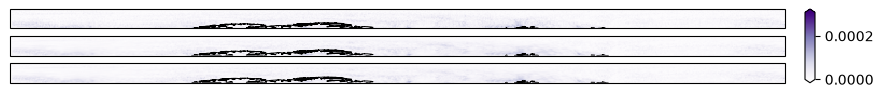

In [ ]:
lonmin, lonmax = -180, 180
latmin, latmax =   81,  90


cmap = plt.get_cmap('Purples')

fig, ax = plt.subplots(3, 1, figsize=(10,1), subplot_kw={'projection': ccrs.PlateCarree()})
bin_ini = ax[0].pcolormesh(ds_ini.longitude, ds_ini.latitude, ds_ini.sensitivity.sum('height'), cmap=cmap, transform=ccrs.PlateCarree())
nc_ini = ax[1].pcolormesh(ds_mr_ini.longitude, ds_mr_ini.latitude, ds_mr_ini.sum('height'), cmap=cmap, transform=ccrs.PlateCarree())
diff = ax[2].pcolormesh(ds_mass_ini.longitude, ds_mass_ini.latitude, ds_mass_ini.sum('height'), cmap=cmap, transform=ccrs.PlateCarree())

for axs in ax.flatten():
    axs.grid()
    axs.add_feature(cfeature.COASTLINE, linewidth=0.7)
    axs.add_feature(cfeature.BORDERS, linewidth=0.5, linestyle='--', alpha=0.7)
    axs.set_extent([lonmin, lonmax, latmin, latmax], crs=ccrs.PlateCarree())

all_axes = ax[:]
bbox = mtransforms.Bbox.union([ax.get_position() for ax in all_axes])
cbar_width = 0.01
cbar_pad = 0.01
cax = fig.add_axes([
    bbox.x1 + cbar_pad + cbar_width,                       
    bbox.y0,
    cbar_width,
    bbox.height,          
])
cb = fig.colorbar(bin_ini, orientation='vertical', cax=cax,
                 extend='both', shrink=0.8) 

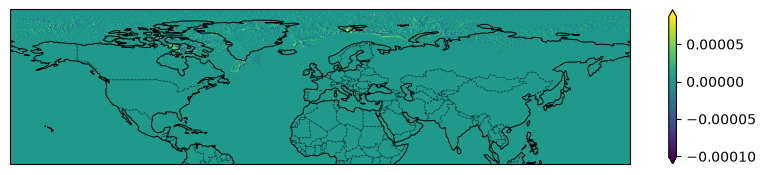

In [ ]:
lonmin, lonmax = -180, 180
latmin, latmax =   0,  90

diff = ds_ini.sensitivity.sum('height') - ds_mass_ini.sum('height')

fig, ax = plt.subplots(1, 1, figsize=(10,4), subplot_kw={'projection': ccrs.PlateCarree()})
d = ax.pcolormesh(diff.longitude, diff.latitude, diff)

ax.grid()
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.5, linestyle='--', alpha=0.7)
ax.set_extent([lonmin, lonmax, latmin, latmax], crs=ccrs.PlateCarree())


fig.colorbar(d, extend='both', shrink=0.5)


In [ ]:
ds_ini_vert = ds_ini.sensitivity.sum(dim=['latitude', 'longitude'])

In [ ]:
ds_mr_ini_vert = ds_mr_ini.sum(dim=['latitude', 'longitude'])
ds_mass_ini_vert = ds_mass_ini.sum(dim=['latitude', 'longitude'])

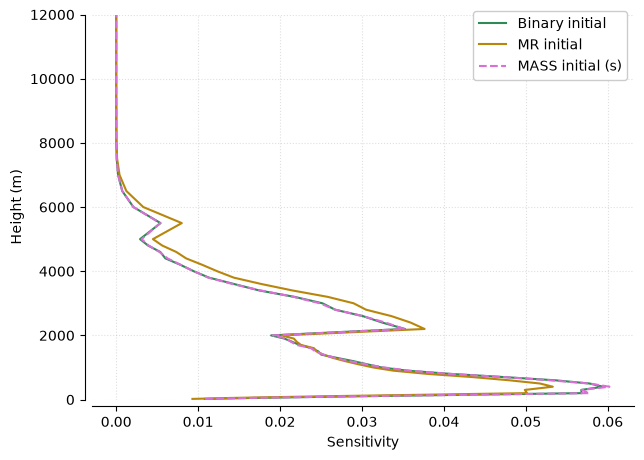

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(7,5))
ax.plot(ds_ini_vert, ds_ini_vert.height, label='Binary initial', color='seagreen')
ax.plot(ds_mr_ini_vert, ds_ini_vert.height, label='MR initial', color='darkgoldenrod')
ax.plot(ds_mass_ini_vert, ds_ini_vert.height, linestyle='--', label='MASS initial (s)', color='orchid')

ax.set_ylim(0, 12000)

ax.grid(linestyle=':', alpha=0.4)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))

ax.set_ylabel('Height (m)')
ax.set_xlabel('Sensitivity')
fig.legend(bbox_to_anchor=(0.5, 0.9, 0.4, 0.), frameon=True, framealpha=1)

In [ ]:
ds_mass_ini.sel(latitude=89.5).sum(dim=['longitude', 'height'])

<xarray.DataArray 'spec001_mass' ()> Size: 4B
array(0.00161125, dtype=float32)
Coordinates:
    time      datetime64[ns] 8B 1991-06-26T12:00:00
    latitude  float32 4B 89.5
Attributes:
    units:        s
    long_name:    AIRTRACER
    weightmolar:  29.0

In [ ]:
290000*ds_mass_ini.sel(latitude=slice(0,29.6)).sum(dim=['latitude', 'longitude', 'height'])

<xarray.DataArray 'spec001_mass' ()> Size: 4B
array(0., dtype=float32)
Coordinates:
    time     datetime64[ns] 8B 1991-06-26T12:00:00
Attributes:
    units:        s
    long_name:    AIRTRACER
    weightmolar:  29.0

## test if northern boundary fucks with data as well

In [10]:
ds_gridded_mass = ds_gridded_mass.isel(time=slice(None, None, -1))


In [25]:
ds_gridded_mass.isel(time=200).sum(dim=['latitude', 'longitude', 'height']).values

array(3600., dtype=float32)

In [24]:
ds_gridded_mass.isel(time=303).sum(dim=['latitude', 'longitude', 'height']).values

array(3551.9983, dtype=float32)

In [20]:
ds_gridded_mass.isel(time=303).sel(latitude=89).sum(dim=['longitude', 'height']).values/3600

np.float32(0.051738154)

In [22]:
ds_problematic_north = (ds_gridded_mass.isel(time=200).sum(dim='height')/3600).load()

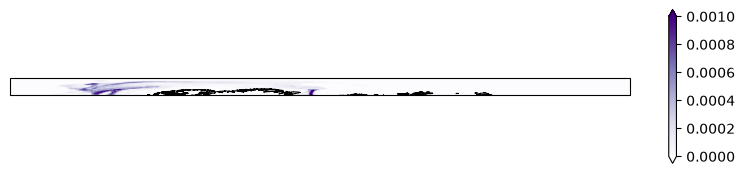

In [23]:
lonmin, lonmax = -180, 180
latmin, latmax =   80,  90

cmap = plt.get_cmap('Purples')
norm = Normalize(vmin=0, vmax=0.001)


fig, ax = plt.subplots(1, 1, figsize=(10,4), subplot_kw={'projection': ccrs.PlateCarree()})
d = ax.pcolormesh(ds_problematic_north.longitude, ds_problematic_north.latitude, ds_problematic_north,
                  cmap=cmap, transform=ccrs.PlateCarree(), norm=norm)

ax.grid()
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.5, linestyle='--', alpha=0.7)
ax.set_extent([lonmin, lonmax, latmin, latmax], crs=ccrs.PlateCarree())


fig.colorbar(d, extend='both', shrink=0.5)